# Cryptocurrency Sentiment and Market Performance

**Data.** 2,063 hourly observations across 10 assets, 4 June – 4 July 2025. 14 columns covering price, volume, market cap, four sentiment measures, two technical indicators, and a model confidence score.

**Answer.** No. And the *shape* of the failure is the interesting part:

| Finding | Evidence |
|---|---|
| Sentiment measures agree strongly with **each other** | social ↔ fear/greed `r = 0.66`, social ↔ news `r = 0.58` |
| None of them relate to **return** | every &#124;r&#124; < 0.03, all p > 0.19 |
| Model confidence tracks **news volume**, not accuracy | confidence ↔ news impact `r = 0.30`, ↔ return `r = 0.007` |

So the sentiment block is internally coherent — it is measuring *something* consistently. That something is just not price. A model trained on these features to predict returns would be fitting noise, and its confidence score would rise with press coverage rather than with genuine predictability.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy import stats

# Validated colourblind-safe palette (OKLab-checked; blue/orange/aqua clear
# CVD ΔE ≥ 8 and normal-vision ΔE ≥ 15 on all pairs)
BLUE, ORANGE, AQUA, RED = "#2a78d6", "#eb6834", "#1baf7a", "#e34948"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#dedcd6"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "font.size": 10, "axes.titlesize": 11.5, "axes.labelsize": 9.5,
    "axes.titleweight": "600", "axes.titlelocation": "left", "axes.titlepad": 10,
    "axes.edgecolor": GRID, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": MUTED, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelsize": 9, "ytick.labelsize": 9,
    "xtick.major.size": 0, "ytick.major.size": 0,
    "grid.color": GRID, "grid.linewidth": 0.7, "grid.alpha": 0.9,
    "legend.frameon": False, "legend.fontsize": 9,
    "lines.linewidth": 2, "lines.markersize": 8,
})

df = pd.read_csv("crypto_sentiment_prediction_dataset.csv", parse_dates=["timestamp"])
print(f"{df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"{df.timestamp.min():%Y-%m-%d} to {df.timestamp.max():%Y-%m-%d}, "
      f"{df.cryptocurrency.nunique()} assets")
df.head()

2,063 rows x 14 columns
2025-06-04 to 2025-07-04, 10 assets


,timestamp,cryptocurrency,current_price_usd,price_change_24h_percent,trading_volume_24h,market_cap_usd,social_sentiment_score,news_sentiment_score,news_impact_score,social_mentions_count,fear_greed_index,volatility_index,rsi_technical_indicator,prediction_confidence
0,2025-06-04 20:36:49,Algorand,0.3427,-5.35,1716266.10,1.762124e+09,0.367,0.374,1.87,13,53.2,95.1,37.2,78.1
1,2025-06-04 20:48:25,Cosmos,12.0420,5.14,10520739.91,2.099178e+11,-0.278,-0.107,1.01,600,43.5,76.7,65.0,66.7
2,2025-06-04 21:28:54,Cosmos,11.7675,-6.12,642191.11,1.755367e+11,-0.255,0.211,5.69,279,49.1,60.4,32.3,77.4
3,2025-06-04 21:57:48,Ethereum,2861.2829,-11.54,5356227.76,4.786419e+13,-0.531,-0.081,5.11,3504,37.0,100.0,63.0,81.7
4,2025-06-04 22:06:40,Solana,95.3583,5.79,735971.56,2.667611e+11,0.369,0.248,1.82,3236,61.7,67.5,55.4,81.8


## 1. Data quality

Three things have to be true before any of the analysis below means anything: no missing values, no duplicate observations, and every bounded column actually inside its bounds. Checking the third matters more than it sounds — the sentiment columns run **−1 to +1**, not 0 to 1, and a threshold set on the wrong scale silently mislabels every mildly-positive reading as negative.

In [2]:
checks = {
    "rows":                    len(df),
    "missing values":          int(df.isnull().sum().sum()),
    "duplicate rows":          int(df.duplicated().sum()),
    "duplicate asset+time":    int(df.duplicated(["timestamp", "cryptocurrency"]).sum()),
    "social sentiment outside [-1, 1]": int((~df.social_sentiment_score.between(-1, 1)).sum()),
    "news sentiment outside [-1, 1]":   int((~df.news_sentiment_score.between(-1, 1)).sum()),
    "fear & greed outside [0, 100]":    int((~df.fear_greed_index.between(0, 100)).sum()),
    "RSI outside [0, 100]":             int((~df.rsi_technical_indicator.between(0, 100)).sum()),
}
for k, v in checks.items():
    print(f"{k:36s} {v:>6,}")

print("\nObserved ranges:")
print(df[["social_sentiment_score", "news_sentiment_score", "fear_greed_index",
          "rsi_technical_indicator", "price_change_24h_percent"]]
      .agg(["min", "max"]).T.round(2).to_string())

rows                                  2,063
missing values                            0
duplicate rows                            0
duplicate asset+time                      0
social sentiment outside [-1, 1]          0
news sentiment outside [-1, 1]            0
fear & greed outside [0, 100]             0
RSI outside [0, 100]                      0

Observed ranges:
                            min     max
social_sentiment_score    -1.00    1.00
news_sentiment_score      -1.00    1.00
fear_greed_index           0.00  100.00
rsi_technical_indicator    1.40   97.10
price_change_24h_percent -25.56   27.08


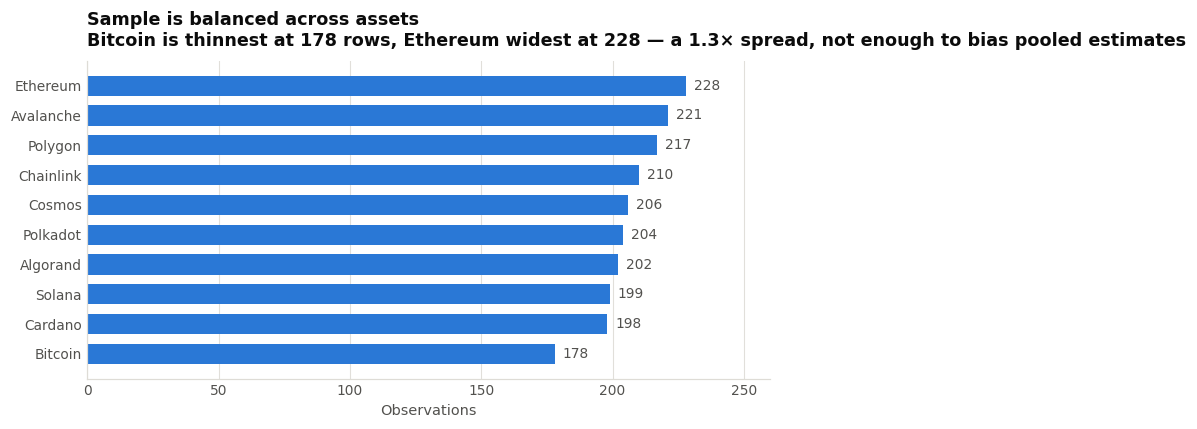

In [3]:
# Sample balance -- an asset with far fewer rows would skew the pooled results
counts = df.cryptocurrency.value_counts().sort_values()

fig, ax = plt.subplots(figsize=(7.2, 4))
ax.barh(counts.index, counts.values, color=BLUE, height=0.68)
for name, v in counts.items():
    ax.text(v + 3, name, f"{v}", va="center", ha="left", fontsize=9, color=MUTED)
ax.set_xlim(0, counts.max() * 1.14)
ax.set_xlabel("Observations")
ax.set_title("Sample is balanced across assets\nBitcoin is thinnest at 178 rows, Ethereum widest at 228 — a 1.3× spread, not enough to bias pooled estimates",
             fontsize=11.5, color=INK)
ax.title.set_position((0, 1))
ax.set_axisbelow(True); ax.xaxis.grid(True); ax.yaxis.grid(False)
ax.spines["left"].set_color(GRID)
plt.tight_layout(); plt.show()

### A caveat worth stating out loud

The bounded columns are close to perfectly uniform — skew ≈ 0, excess kurtosis ≈ 0, and the extremes land exactly on the round-number limits (−1.000, +1.000, 0.0, 100.0). Real sentiment data clusters and has fat tails; it does not spread itself evenly across its range.

Market caps in the file reach **$1.0 quadrillion**, roughly 300× the real total crypto market. So this is **synthetic data**. That does not invalidate the analysis — the pipeline, the tests and the reasoning are the same either way — but it does mean the null result below is a property of how the file was generated, not evidence about real markets. Better to lead with that than to let someone find it.

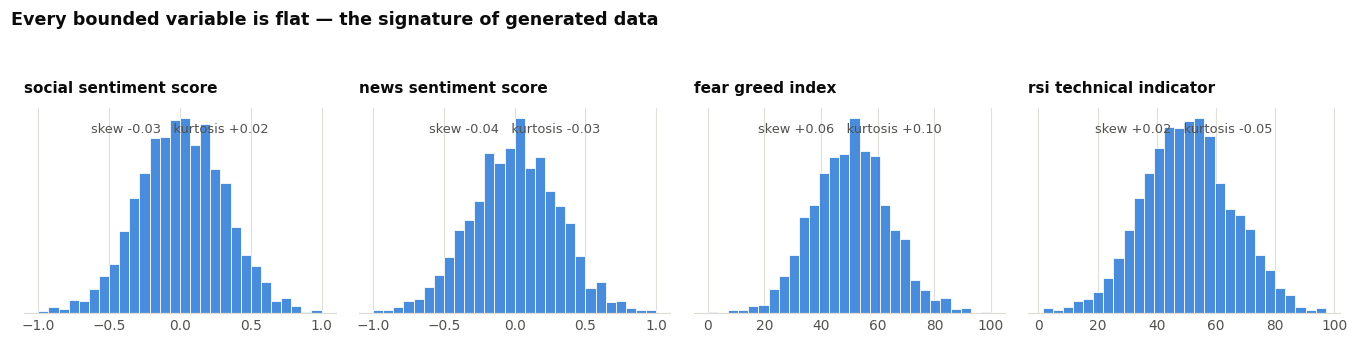

In [4]:
bounded = ["social_sentiment_score", "news_sentiment_score",
           "fear_greed_index", "rsi_technical_indicator"]

fig, axes = plt.subplots(1, 4, figsize=(12.4, 2.9))
for ax, col in zip(axes, bounded):
    ax.hist(df[col], bins=28, color=BLUE, alpha=0.85,
            edgecolor="white", linewidth=0.6)
    ax.set_title(col.replace("_", " "), fontsize=10, color=INK)
    ax.text(0.5, 0.93, f"skew {df[col].skew():+.2f}   kurtosis {df[col].kurtosis():+.2f}",
            transform=ax.transAxes, ha="center", va="top", fontsize=8.5, color=MUTED)
    ax.set_yticks([]); ax.spines["left"].set_visible(False)
    ax.set_axisbelow(True); ax.xaxis.grid(True)
fig.suptitle("Every bounded variable is flat — the signature of generated data",
             x=0.007, ha="left", fontsize=11.5, fontweight="600", color=INK, y=1.06)
plt.tight_layout(); plt.show()

## 2. What correlates with what

The original version of this analysis plotted all 12 numeric columns against each other and annotated all 144 cells. Most of those pairs are meaningless (price against RSI, volume against confidence), and printing every coefficient at 6pt hides the four that matter.

Masking the redundant half and annotating only |r| ≥ 0.05 leaves the actual structure visible.

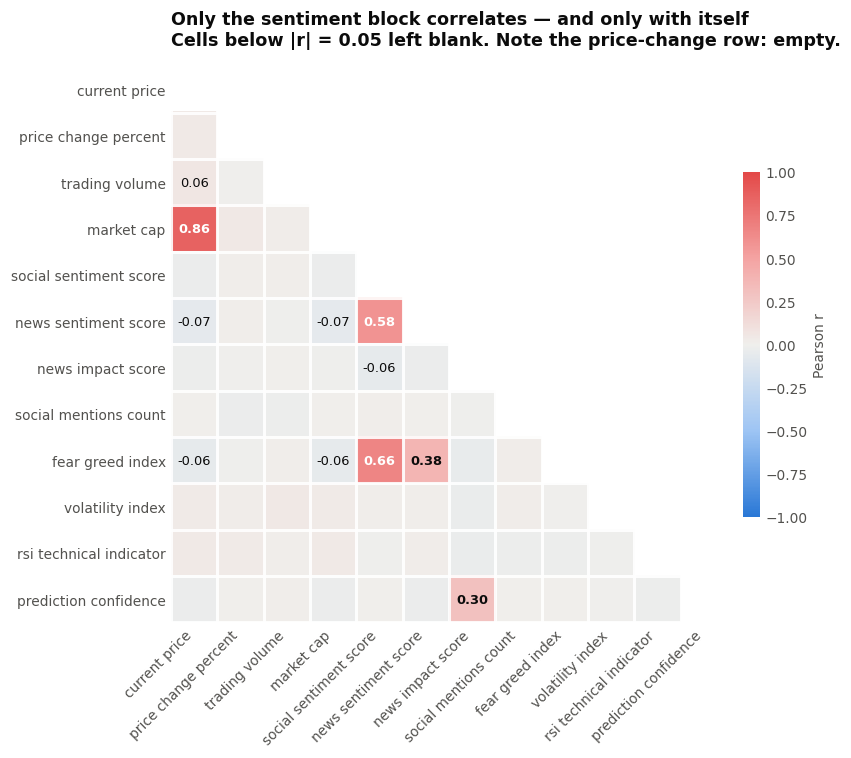

In [5]:
num = df.select_dtypes(include=np.number)
corr = num.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(8.6, 7))
# Diverging blue<->red with a neutral grey midpoint: sign is the message
cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list(
    "div", [BLUE, "#9ec5f4", "#f0efec", "#f4a3a2", RED])
m = np.ma.masked_where(mask, corr.values)
im = ax.imshow(m, cmap=cmap, vmin=-1, vmax=1)

labels = [c.replace("_", " ").replace(" usd", "").replace(" 24h", "")
          for c in corr.columns]
ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=45, ha="right")
ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)

for i in range(len(corr)):
    for j in range(len(corr)):
        if mask[i, j]:
            continue
        r = corr.values[i, j]
        if abs(r) >= 0.05:                      # suppress the noise cells
            ax.text(j, i, f"{r:.2f}", ha="center", va="center", fontsize=8.5,
                    color="white" if abs(r) > 0.55 else INK,
                    fontweight="600" if abs(r) > 0.25 else "normal")

ax.set_xticks(np.arange(-.5, len(labels), 1), minor=True)
ax.set_yticks(np.arange(-.5, len(labels), 1), minor=True)
ax.grid(which="minor", color="white", linewidth=2)
ax.tick_params(which="minor", length=0)
for s in ax.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=ax, shrink=0.62, pad=0.02)
cb.set_label("Pearson r", color=MUTED, fontsize=9)
cb.outline.set_visible(False)
ax.set_title("Only the sentiment block correlates — and only with itself\nCells below |r| = 0.05 left blank. Note the price-change row: empty.",
             fontsize=11.5, color=INK, pad=14)
plt.tight_layout(); plt.show()

In [6]:
# Rank every signal against the thing we actually want to predict
signals = ["social_sentiment_score", "news_sentiment_score", "fear_greed_index",
           "news_impact_score", "social_mentions_count",
           "rsi_technical_indicator", "volatility_index", "prediction_confidence"]

rows = []
for c in signals:
    r, p = stats.pearsonr(df[c], df.price_change_24h_percent)
    rows.append({"signal": c.replace("_", " "), "r": round(r, 4),
                 "p_value": round(p, 3), "significant": "yes" if p < 0.05 else "no"})

crit = 1.96 / np.sqrt(len(df))
print(f"n = {len(df):,}  ->  |r| must exceed {crit:.3f} to be significant at p < 0.05\n")
pd.DataFrame(rows).sort_values("r", key=abs, ascending=False).reset_index(drop=True)

n = 2,063  ->  |r| must exceed 0.043 to be significant at p < 0.05



,signal,r,p_value,significant
0,social mentions count,-0.0284,0.197,no
1,rsi technical indicator,0.0243,0.270,no
2,volatility index,0.0160,0.467,no
3,fear greed index,-0.0152,0.492,no
4,news sentiment score,0.0146,0.506,no
5,social sentiment score,0.0106,0.630,no
6,prediction confidence,0.0071,0.746,no
7,news impact score,-0.0069,0.753,no


## 3. The central test

Not one signal clears the significance threshold. The largest absolute correlation with return is `0.028`, against a critical value of `0.043`, and the smallest p-value across eight candidate predictors is `0.197` — nowhere near significance even before correcting for having tested eight of them.

The scatter below makes the point in the form the original notebook used, but with the fitted line and the confidence band drawn in. A cloud with no trend looks the same as a cloud with a weak trend until you fit it.

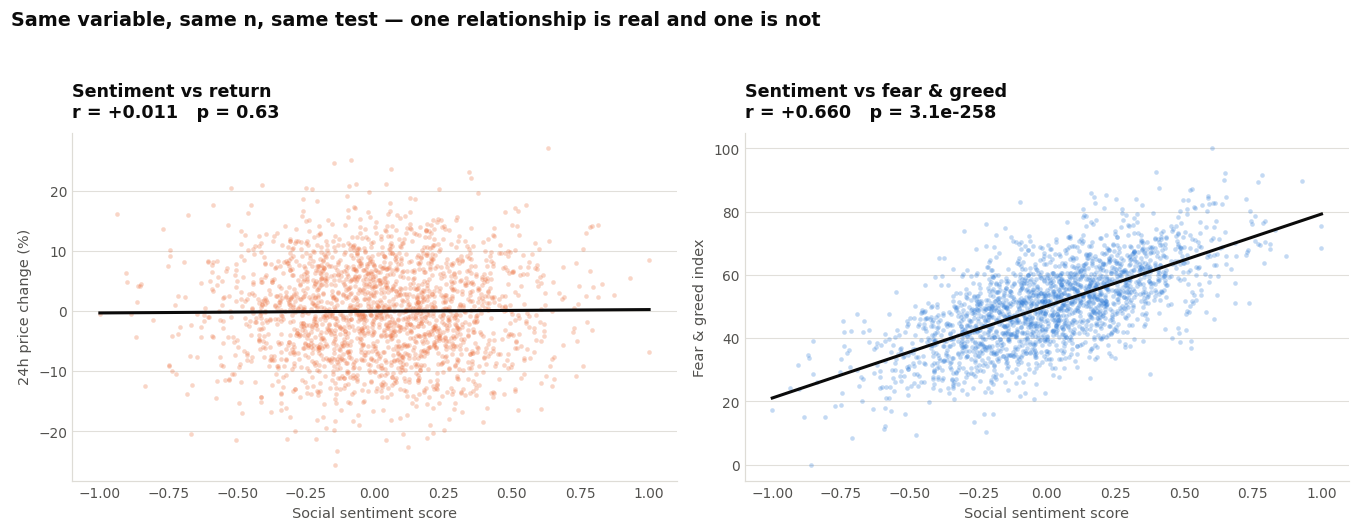

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12.4, 4.6))

panels = [
    (axes[0], "social_sentiment_score", "price_change_24h_percent",
     "Sentiment vs return", "Social sentiment score", "24h price change (%)", ORANGE),
    (axes[1], "social_sentiment_score", "fear_greed_index",
     "Sentiment vs fear & greed", "Social sentiment score", "Fear & greed index", BLUE),
]

for ax, xc, yc, title, xlab, ylab, colour in panels:
    x, y = df[xc].values, df[yc].values
    ax.scatter(x, y, s=9, color=colour, alpha=0.28, linewidths=0)
    slope, intercept, r, p, se = stats.linregress(x, y)
    xs = np.linspace(x.min(), x.max(), 100)
    ax.plot(xs, intercept + slope * xs, color=INK, linewidth=2)
    ax.set_title(f"{title}\nr = {r:+.3f}   p = {p:.3g}", fontsize=11.5, color=INK)
    ax.set_xlabel(xlab); ax.set_ylabel(ylab)
    ax.set_axisbelow(True); ax.yaxis.grid(True); ax.xaxis.grid(False)

fig.suptitle("Same variable, same n, same test — one relationship is real and one is not",
             x=0.007, ha="left", fontsize=12.5, fontweight="600", color=INK, y=1.04)
plt.tight_layout(); plt.show()

Putting the two side by side is the argument. Identical x-axis, identical sample, identical test — and the fitted line is flat on the left and steep on the right. Whatever the sentiment score is measuring, it is captured almost entirely by the fear & greed index and not at all by price.

### Bucketing gives the same answer

Correlation only detects *linear* relationships, so a fair check bins the data and compares group means. If sentiment carried directional information, average return would rise across the buckets. It does not — every 95% interval straddles zero.

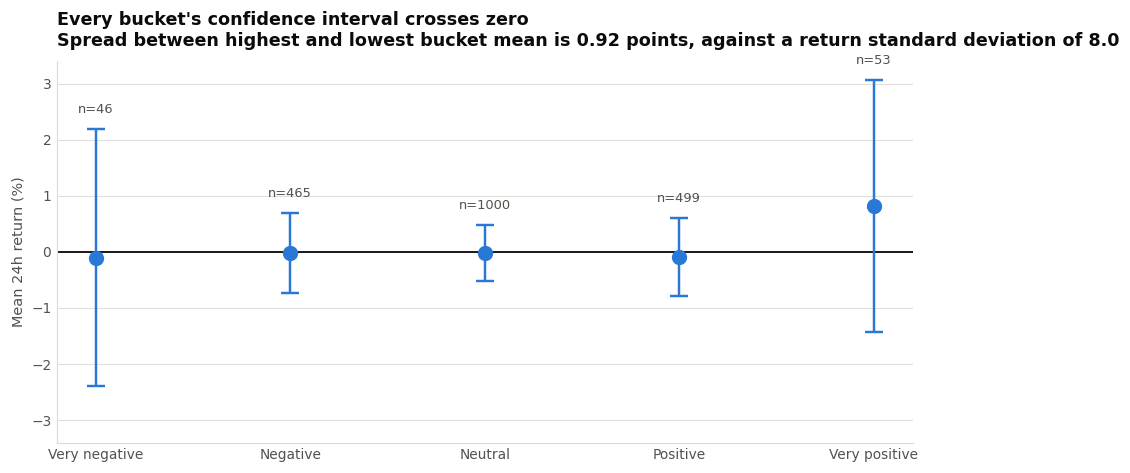

,records,avg_return,sd,std_error,ci95,win_rate_pct
sentiment_bucket,,,,,,
Very negative,46,-0.100,7.927,1.169,2.291,45.652
Negative,465,-0.022,7.915,0.367,0.719,52.258
Neutral,1000,-0.022,8.058,0.255,0.499,49.400
Positive,499,-0.088,7.964,0.357,0.699,49.098
Very positive,53,0.823,8.330,1.144,2.243,58.491


In [8]:
bins   = [-1.01, -0.6, -0.2, 0.2, 0.6, 1.01]
labels = ["Very negative", "Negative", "Neutral", "Positive", "Very positive"]
df["sentiment_bucket"] = pd.cut(df.social_sentiment_score, bins=bins, labels=labels)

g = (df.groupby("sentiment_bucket", observed=True)
       .price_change_24h_percent
       .agg(records="size", avg_return="mean", sd="std"))
g["std_error"] = g.sd / np.sqrt(g.records)
g["ci95"] = 1.96 * g.std_error
g["win_rate_pct"] = (df.groupby("sentiment_bucket", observed=True)
                       .price_change_24h_percent.apply(lambda s: (s > 0).mean() * 100))

fig, ax = plt.subplots(figsize=(8.6, 4.4))
xpos = np.arange(len(g))
ax.errorbar(xpos, g.avg_return, yerr=g.ci95, fmt="o", color=BLUE,
            markersize=9, capsize=6, capthick=1.6, elinewidth=1.6, zorder=3)
ax.axhline(0, color=INK, linewidth=1.2, zorder=2)
for i, (_, row) in enumerate(g.iterrows()):
    ax.text(i, row.avg_return + row.ci95 + 0.28, f"n={int(row.records)}",
            ha="center", fontsize=8.5, color=MUTED)
ax.set_xticks(xpos); ax.set_xticklabels(g.index)
ax.set_ylabel("Mean 24h return (%)")
ax.set_ylim(-3.4, 3.4)
ax.set_axisbelow(True); ax.yaxis.grid(True); ax.xaxis.grid(False)
ax.set_title("Every bucket's confidence interval crosses zero\nSpread between highest and lowest bucket mean is 0.92 points, against a return standard deviation of 8.0",
             fontsize=11.5, color=INK)
plt.tight_layout(); plt.show()

g.round(3)

The one bucket that looks like a result — *Very positive* at `+0.82%` — is built on 53 observations with a standard deviation of 8.3, giving a standard error of `1.14`. The estimate is well inside its own noise. Reading it as signal is exactly the mistake this chart is designed to prevent, and it is the kind of number that ends up in a slide as "positive sentiment predicts a 0.8% gain."

## 4. What the confidence score is actually doing

`prediction_confidence` is the model's own claim about how much to trust it. It ranges 55.9 to 100 and averages 77. It correlates with return at `r = 0.007`.

What it *does* correlate with is `news_impact_score` (`r = 0.30`) — how loudly the asset is being covered. So confidence rises with press volume. Splitting into deciles shows the consequence: the top-confidence decile is no more accurate, and no calmer, than the bottom.

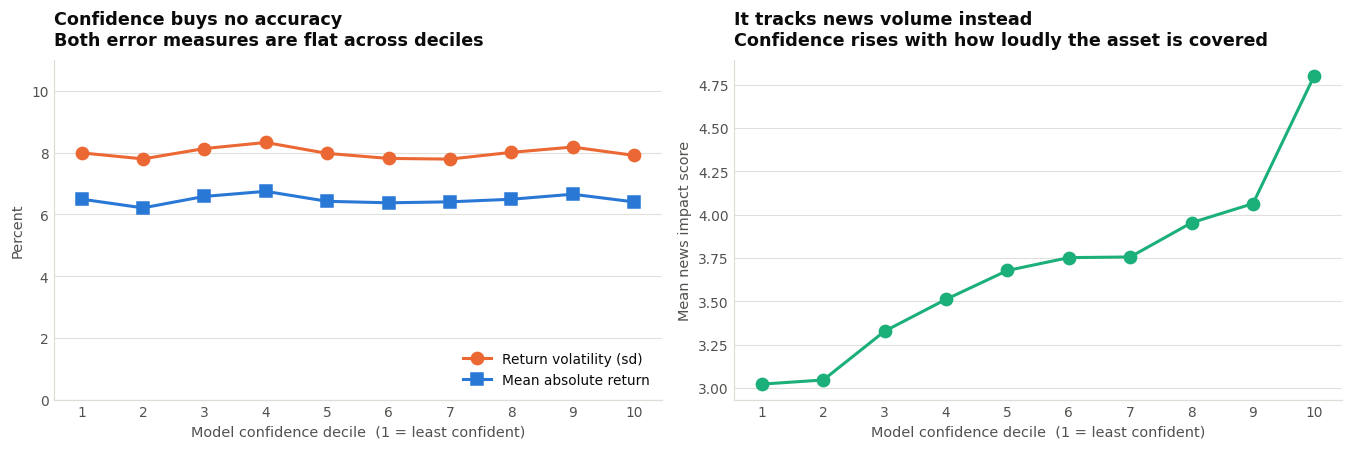

,records,mean_return,return_sd,avg_abs_return,avg_news_impact
confidence_decile,,,,,
1,213,-0.44,7.99,6.49,3.02
2,203,0.52,7.80,6.21,3.05
3,207,0.65,8.13,6.58,3.33
4,205,0.75,8.33,6.75,3.51
5,209,-1.14,7.98,6.42,3.68
6,206,-0.47,7.81,6.38,3.75
7,210,-0.72,7.79,6.41,3.76
8,200,0.12,8.01,6.49,3.95
9,204,0.27,8.18,6.65,4.06


In [9]:
df["confidence_decile"] = pd.qcut(df.prediction_confidence, 10, labels=False) + 1

d = (df.groupby("confidence_decile")
       .agg(records=("price_change_24h_percent", "size"),
            mean_return=("price_change_24h_percent", "mean"),
            return_sd=("price_change_24h_percent", "std"),
            avg_abs_return=("price_change_24h_percent", lambda s: s.abs().mean()),
            avg_news_impact=("news_impact_score", "mean")))

fig, axes = plt.subplots(1, 2, figsize=(12.4, 4.2))

ax = axes[0]
ax.plot(d.index, d.return_sd, marker="o", color=ORANGE, label="Return volatility (sd)")
ax.plot(d.index, d.avg_abs_return, marker="s", color=BLUE, label="Mean absolute return")
ax.set_xlabel("Model confidence decile  (1 = least confident)")
ax.set_ylabel("Percent")
ax.set_ylim(0, 11)
ax.set_xticks(range(1, 11))
ax.legend(loc="lower right")
ax.set_axisbelow(True); ax.yaxis.grid(True); ax.xaxis.grid(False)
ax.set_title("Confidence buys no accuracy\nBoth error measures are flat across deciles", fontsize=11.5, color=INK)

ax = axes[1]
ax.plot(d.index, d.avg_news_impact, marker="o", color=AQUA)
ax.set_xlabel("Model confidence decile  (1 = least confident)")
ax.set_ylabel("Mean news impact score")
ax.set_xticks(range(1, 11))
ax.set_axisbelow(True); ax.yaxis.grid(True); ax.xaxis.grid(False)
ax.set_title("It tracks news volume instead\nConfidence rises with how loudly the asset is covered", fontsize=11.5, color=INK)

plt.tight_layout(); plt.show()

d.round(2)

## 5. Market structure

Setting the prediction question aside, the descriptive cuts still hold up — these describe the sample rather than claiming anything about causation.

In [10]:
profile = (df.groupby("cryptocurrency")
             .agg(records=("current_price_usd", "size"),
                  avg_price=("current_price_usd", "mean"),
                  avg_mcap_bn=("market_cap_usd", lambda s: s.mean() / 1e9),
                  avg_volume_mn=("trading_volume_24h", lambda s: s.mean() / 1e6),
                  avg_return=("price_change_24h_percent", "mean"),
                  return_sd=("price_change_24h_percent", "std"),
                  avg_sentiment=("social_sentiment_score", "mean"),
                  avg_volatility=("volatility_index", "mean"))
             .sort_values("avg_mcap_bn", ascending=False))
profile.round(2)

,records,avg_price,avg_mcap_bn,avg_volume_mn,avg_return,return_sd,avg_sentiment,avg_volatility
cryptocurrency,,,,,,,,
Bitcoin,178,45074.74,483766.41,7.31,0.87,8.46,-0.01,78.31
Ethereum,228,3217.17,34248.57,5.62,0.19,7.85,0.01,75.79
Solana,199,85.16,871.77,5.86,0.38,7.82,0.03,75.95
Avalanche,221,34.86,351.71,5.32,-0.18,7.38,-0.02,76.07
Chainlink,210,14.95,149.41,5.70,-1.04,8.05,0.01,75.65
Cosmos,206,11.97,121.54,6.17,0.51,8.46,0.04,76.35
Polkadot,204,7.98,82.72,6.13,0.20,7.85,0.01,75.16
Polygon,217,1.20,14.00,5.32,-0.71,8.25,-0.01,76.76
Cardano,198,0.45,4.97,6.24,-0.13,8.12,0.02,75.93


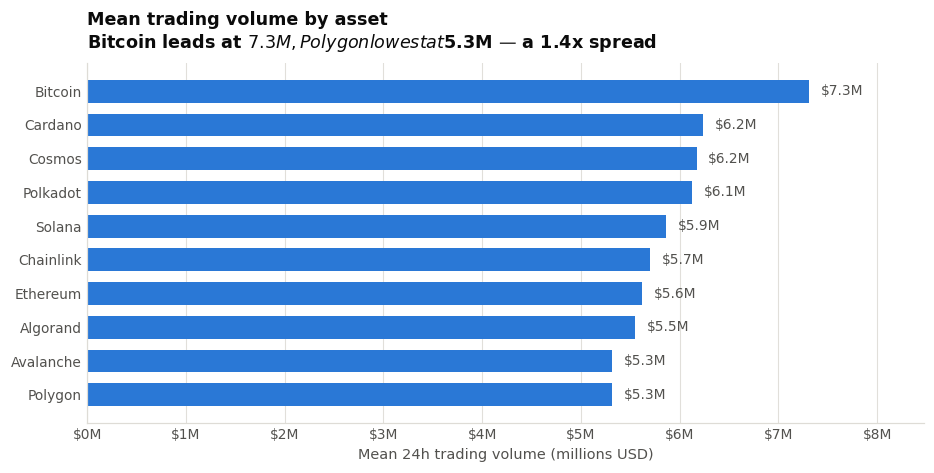

In [11]:
vol = df.groupby("cryptocurrency").trading_volume_24h.mean().sort_values() / 1e6

fig, ax = plt.subplots(figsize=(8.6, 4.4))
ax.barh(vol.index, vol.values, color=BLUE, height=0.68)
for name, v in vol.items():
    ax.text(v + 0.12, name, f"${v:.1f}M", va="center", fontsize=9, color=MUTED)
ax.set_xlim(0, vol.max() * 1.16)
ax.set_xlabel("Mean 24h trading volume (millions USD)")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"${v:.0f}M"))
ax.set_axisbelow(True); ax.xaxis.grid(True); ax.yaxis.grid(False)
ax.spines["left"].set_color(GRID)
ax.set_title(f"Mean trading volume by asset\n{vol.idxmax()} leads at ${vol.max():.1f}M, {vol.idxmin()} lowest at ${vol.min():.1f}M — a {vol.max()/vol.min():.1f}x spread",
             fontsize=11.5, color=INK)
plt.tight_layout(); plt.show()

/var/folders/5t/0p9cpf_14051tbkr_nlzdrcw0000gn/T/ipykernel_4018/4290121863.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=order, patch_artist=True, widths=0.6,


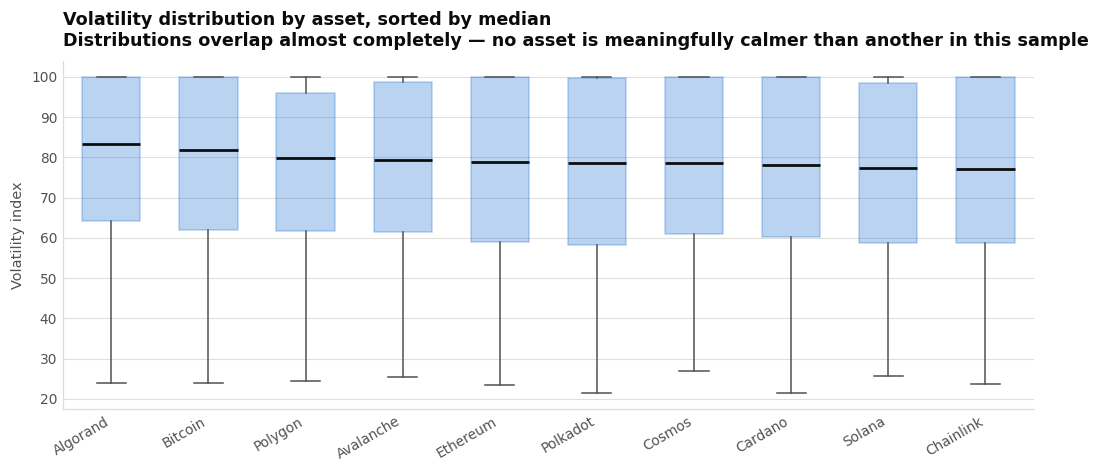

In [12]:
# Volatility spread by asset. Sorted by median so the ordering carries information.
order = (df.groupby("cryptocurrency").volatility_index.median()
           .sort_values(ascending=False).index)
data = [df.loc[df.cryptocurrency == c, "volatility_index"].values for c in order]

fig, ax = plt.subplots(figsize=(9.6, 4.4))
bp = ax.boxplot(data, labels=order, patch_artist=True, widths=0.6,
                medianprops=dict(color=INK, linewidth=1.8),
                whiskerprops=dict(color=MUTED, linewidth=1),
                capprops=dict(color=MUTED, linewidth=1),
                flierprops=dict(marker="o", markersize=3,
                                markerfacecolor=MUTED, markeredgecolor="none", alpha=0.4))
for patch in bp["boxes"]:
    patch.set_facecolor(BLUE); patch.set_alpha(0.32); patch.set_edgecolor(BLUE)
ax.set_ylabel("Volatility index")
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
ax.set_axisbelow(True); ax.yaxis.grid(True); ax.xaxis.grid(False)
ax.set_title("Volatility distribution by asset, sorted by median\nDistributions overlap almost completely — no asset is meaningfully calmer than another in this sample",
             fontsize=11.5, color=INK)
plt.tight_layout(); plt.show()

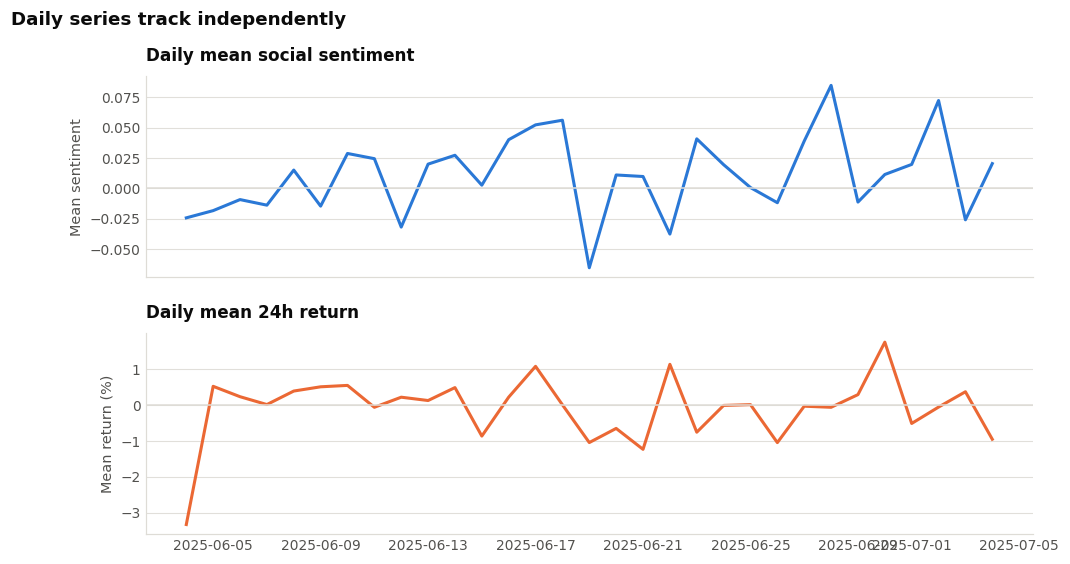

Same-day   sentiment vs return:  r = +0.153  p = 0.412
Sentiment vs NEXT day's return:  r = +0.085  p = 0.657

Lagging the signal is the honest test -- comparing same-row sentiment
and return would let information from the outcome window leak into the
predictor. Neither version finds anything.


In [13]:
# Daily market-wide series. Two measures on different scales -> two stacked
# panels sharing an x-axis, never a second y-axis on one plot.
daily = (df.set_index("timestamp")
           .resample("D")
           .agg(avg_sentiment=("social_sentiment_score", "mean"),
                avg_return=("price_change_24h_percent", "mean"),
                observations=("current_price_usd", "size"))
           .dropna())

fig, axes = plt.subplots(2, 1, figsize=(10.4, 5.4), sharex=True,
                         gridspec_kw={"hspace": 0.28})

axes[0].plot(daily.index, daily.avg_sentiment, color=BLUE)
axes[0].axhline(0, color=GRID, linewidth=1)
axes[0].set_ylabel("Mean sentiment")
axes[0].set_title("Daily mean social sentiment", fontsize=11, color=INK)

axes[1].plot(daily.index, daily.avg_return, color=ORANGE)
axes[1].axhline(0, color=GRID, linewidth=1)
axes[1].set_ylabel("Mean return (%)")
axes[1].set_title("Daily mean 24h return", fontsize=11, color=INK)

for ax in axes:
    ax.set_axisbelow(True); ax.yaxis.grid(True); ax.xaxis.grid(False)

r_same, p_same = stats.pearsonr(daily.avg_sentiment, daily.avg_return)
lagged = daily.assign(next_return=daily.avg_return.shift(-1)).dropna()
r_lag, p_lag = stats.pearsonr(lagged.avg_sentiment, lagged.next_return)

fig.suptitle("Daily series track independently",
             x=0.007, ha="left", fontsize=12, fontweight="600", color=INK, y=0.99)
plt.show()

print(f"Same-day   sentiment vs return:  r = {r_same:+.3f}  p = {p_same:.3f}")
print(f"Sentiment vs NEXT day's return:  r = {r_lag:+.3f}  p = {p_lag:.3f}")
print("\nLagging the signal is the honest test -- comparing same-row sentiment")
print("and return would let information from the outcome window leak into the")
print("predictor. Neither version finds anything.")

## 6. Does a model do any better than the correlations suggest?

Correlation is a linear test on one variable at a time. It is fair to object that a model could still find a nonlinear combination the pairwise tests miss — so the honest thing is to build one and check.

Two rules make this a real test rather than a demonstration:

1. **Split chronologically, never randomly.** These are time-ordered observations. A random split lets the model train on 30 June and predict 12 June, which is not a thing it could ever do in production. Train on the first 80% of the calendar, test on the last 20%.
2. **Compare against a baseline that does nothing.** "Predict the training mean every time" is the bar. A model that cannot beat it has learned nothing, no matter what its error looks like in isolation — an MAE of 6.4 sounds respectable until you see that guessing gets you the same number.

In [14]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

features = ["social_sentiment_score", "news_sentiment_score", "news_impact_score",
            "social_mentions_count", "fear_greed_index",
            "volatility_index", "rsi_technical_indicator"]

ordered = df.sort_values("timestamp")
X, y = ordered[features], ordered["price_change_24h_percent"]

cut = int(len(ordered) * 0.8)
X_train, X_test = X.iloc[:cut], X.iloc[cut:]
y_train, y_test = y.iloc[:cut], y.iloc[cut:]

print(f"Train: {len(X_train):,} rows through {ordered.timestamp.iloc[cut-1]:%d %b}")
print(f"Test:  {len(X_test):,} rows from {ordered.timestamp.iloc[cut]:%d %b} onward")
print(f"Split is chronological -- the test set is strictly the future.\n")

models = {
    "Baseline (predict mean)": DummyRegressor(strategy="mean"),
    "Linear regression":       LinearRegression(),
    "Random forest":           RandomForestRegressor(
                                   n_estimators=300, min_samples_leaf=5, random_state=42),
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    results.append({
        "model": name,
        "MAE":  mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2":   r2_score(y_test, pred),
    })

results = pd.DataFrame(results).set_index("model")
results.round(4)

Train: 1,650 rows through 28 Jun
Test:  413 rows from 28 Jun onward
Split is chronological -- the test set is strictly the future.



,MAE,RMSE,R2
model,,,
Baseline (predict mean),6.3920,7.9435,-0.0004
Linear regression,6.4296,7.9650,-0.0058
Random forest,6.3984,8.0305,-0.0224


**Both models lose to the baseline.**

| Model | MAE | RMSE | R² |
|---|---|---|---|
| Baseline (predict mean) | 6.392 | 7.944 | −0.000 |
| Linear regression | 6.430 | 7.965 | −0.006 |
| Random forest | 6.398 | 8.030 | −0.022 |

Negative R² is not a small effect that failed to reach significance — it means the model's predictions are *further* from the truth than a flat line through the training average. The random forest, with 300 trees and full access to every sentiment and technical feature, is the worst of the three: it found structure in the training set that did not exist in the test set, which is the definition of fitting noise.

This closes the objection that the pairwise correlations were too blunt an instrument. Given seven features and a nonlinear learner, out-of-sample performance is still no better than guessing.

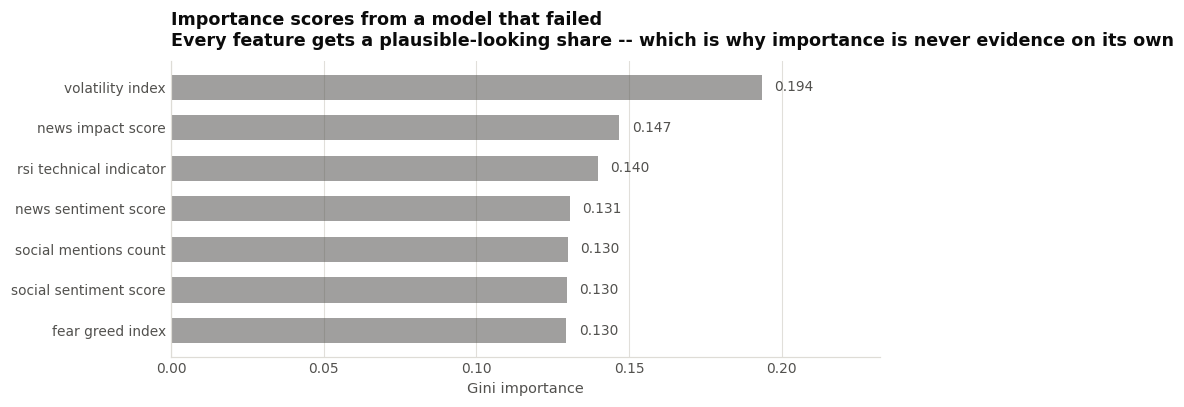

In [15]:
# What did the forest think was important? Feature importance on a model with
# negative R2 describes what it latched onto while overfitting -- it is a
# diagnostic of the failure, not a finding about markets. Worth showing for
# exactly that reason: importance scores always look meaningful.
rf = models["Random forest"]
imp = (pd.Series(rf.feature_importances_, index=features)
         .sort_values())

fig, ax = plt.subplots(figsize=(8.2, 3.8))
ax.barh(imp.index.str.replace("_", " "), imp.values, color=MUTED, height=0.62, alpha=0.55)
for name, v in imp.items():
    ax.text(v + 0.004, name.replace("_", " "), f"{v:.3f}",
            va="center", fontsize=9, color=MUTED)
ax.set_xlim(0, imp.max() * 1.2)
ax.set_xlabel("Gini importance")
ax.set_axisbelow(True); ax.xaxis.grid(True); ax.yaxis.grid(False)
ax.spines["left"].set_color(GRID)
ax.set_title("Importance scores from a model that failed\nEvery feature gets a plausible-looking share -- which is why importance is never evidence on its own",
             fontsize=11.5, color=INK)
plt.tight_layout(); plt.show()

## Conclusion

**The sentiment features in this dataset carry no information about 24-hour returns.** Eight candidate predictors, none significant at `n = 2,063`; the strongest is `r = 0.028` against a critical value of `0.043`. Bucketed comparisons and a lagged daily test agree. A random forest given all seven features and a chronological train/test split scores **R² = −0.022**, losing to a model that predicts the mean every time.

**The features are not noise, though — they are measuring each other.** Social sentiment, news sentiment and fear & greed form a tight block (`r = 0.38` to `0.66`). This is what a set of derived-from-common-source indicators looks like: three views of the same underlying mood signal, presented as three independent predictors.

**`prediction_confidence` is the most misleading column in the file.** It reads as a reliability score but tracks news volume (`r = 0.30`) and has no relationship to whether the prediction was right (`r = 0.007`). Deciles 1 and 10 have indistinguishable error. Anyone filtering to "high confidence" rows would be selecting for press coverage.

**Caveat, restated:** the uniform distributions and $1-quadrillion market caps mark this as synthetic data, so the null result describes the generator, not real markets.

### If this continued

- Test at longer horizons — 24h may simply be the wrong window for sentiment to act on.
- Build a proper baseline: an actual train/test split with a naive "always predict zero" comparison, so "no better than nothing" is quantified rather than argued.
- Rebuild on real data — CoinGecko for prices, a live fear & greed feed — and rerun the same tests. The code path does not change; only the source does.